In [34]:
import duckdb
import numpy as np
import geopandas as gpd
import shapely
import contextily as ctx
from shapely import wkt
from shapely import wkb
from shapely.ops import transform
from shapely.geometry import box
from shapely.geometry import LineString, MultiLineString, box
import folium
import random
import json
import time
import xyzservices.providers as xyz
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from folium.features import DivIcon
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import contextily as ctx
from pyproj import Transformer
 


In [2]:
print(duckdb.__version__)
# The MobilityDuck CI builds and tests the extension against DuckDB v1.5.5, and
# the extension loads only into the DuckDB version it was built for.
assert duckdb.__version__ == '1.5.5'
# The extension built by the MobilityDuck CI, or by a build of MobilityDuck
MOBILITYDUCK_EXTENSION = '/path/to/mobilityduck.duckdb_extension'

1.3.2


In [3]:
connection = duckdb.connect(
    config={'allow_unsigned_extensions' : 'true'}
)

In [4]:
connection = duckdb.connect(
    database='vessels.db',
    config={'allow_unsigned_extensions' : 'true'}
)

In [5]:
connection.execute("INSTALL spatial FROM core_nightly")
connection.execute(f"INSTALL '{MOBILITYDUCK_EXTENSION}'")
connection.load_extension(MOBILITYDUCK_EXTENSION)
connection.load_extension('spatial')

In [6]:
sns.set_context('paper')
sns.set_theme()
sns.set_style('white')

In [7]:
connection.execute("SET threads=1")
connection.execute("SET memory_limit='7000MB'")
connection.execute("SET preserve_insertion_order=false")

In [8]:
def get_trip_colors(n_colors):
    og_colors = list(mcolors.TABLEAU_COLORS.values())
    while len(og_colors) < n_colors:
        og_colors = og_colors * 2
    return random.sample(og_colors, n_colors)

In [43]:
connection.execute('CREATE OR REPLACE TABLE ships (mmsi integer, trip tgeompoint, sog tfloat, cog tfloat);').fetchone 

<bound method PyCapsule.fetchone of <duckdb.duckdb.DuckDBPyConnection object at 0x175dcc470>>

In [44]:
conn_str = "host=localhost port=55432 dbname=Vessels user=postgres password=mysecretpassword"

query = f"""
INSERT INTO ships
SELECT mmsi, trip, sog, cog FROM postgres_scan(
    '{conn_str}',    
    'public',          
    'ships'       
);
"""
result = connection.execute(query).fetchone()

In [9]:
query = "SELECT COUNT(*) FROM ships;"
result = connection.execute(query).fetchone()
result

(3112,)

In [169]:
connection.close()

In [10]:
# Reopen connection and query
connection = duckdb.connect(
    database='vessels.db',
    config={'allow_unsigned_extensions' : 'true'}
)
connection.load_extension(MOBILITYDUCK_EXTENSION)
connection.load_extension('spatial')

In [11]:
query = "SELECT * FROM ships LIMIT 5;"
result = connection.execute(query).df()
result

,mmsi,trip,sog,cog,trajectory
0,2655150,"[160, 133, 23, 0, 46, 2, 94, 0, 224, 26, 0, 0,...",<NA>,<NA>,"[1, 4, 0, 0, 0, 0, 0, 0, 8, 147, 38, 73, 64, 7..."
1,111265586,"[32, 179, 2, 0, 46, 2, 94, 0, 20, 3, 0, 0, 20,...","[64, 45, 1, 0, 33, 2, 94, 0, 88, 2, 0, 0, 88, ...","[192, 133, 1, 0, 33, 2, 94, 0, 9, 3, 0, 0, 9, ...","[1, 4, 0, 0, 0, 0, 0, 0, 133, 248, 70, 73, 194..."
2,211226990,"[128, 132, 13, 0, 46, 2, 94, 0, 113, 15, 0, 0,...","[64, 100, 4, 0, 33, 2, 94, 0, 198, 8, 0, 0, 19...","[192, 194, 7, 0, 33, 2, 94, 0, 131, 15, 0, 0, ...","[1, 4, 0, 0, 0, 0, 0, 0, 137, 83, 4, 73, 64, 1..."
3,211266470,"[224, 184, 8, 0, 46, 2, 94, 0, 246, 9, 0, 0, 2...","[64, 13, 1, 0, 33, 2, 94, 0, 24, 2, 0, 0, 24, ...","[64, 34, 1, 0, 33, 2, 94, 0, 66, 2, 0, 0, 66, ...","[1, 4, 0, 0, 0, 0, 0, 0, 171, 73, 43, 73, 39, ..."
4,211297990,"[96, 81, 26, 0, 46, 2, 94, 0, 18, 30, 0, 0, 18...","[64, 2, 0, 0, 33, 2, 94, 0, 2, 0, 0, 0, 2, 0, ...","[64, 2, 0, 0, 33, 2, 94, 0, 2, 0, 0, 0, 2, 0, ...","[1, 4, 0, 0, 0, 0, 0, 0, 155, 64, 234, 72, 203..."


In [10]:
query = "DESCRIBE ships;"
connection.execute(query).df().head()

,column_name,column_type,null,key,default,extra
0,mmsi,INTEGER,YES,None,None,None
1,trip,TGEOMPOINT,YES,None,None,None
2,sog,TFLOAT,YES,None,None,None
3,cog,TFLOAT,YES,None,None,None


In [12]:
query = "SELECT asText(trip) as trip  FROM ships LIMIT 5;"
connection.execute(query).df().head()

,trip
0,[POINT(682298.1137081726 6398758.164948804)@20...
1,[POINT(817605.5377842414 6207924.339999045)@20...
2,[POINT(542023.500704527 6075299.17791475)@2024...
3,[POINT(701957.2646812306 6005363.221456901)@20...
4,[POINT(479754.3856286277 6041582.630180929)@20...


In [48]:
# Query 6.1. Number of records
query = """SELECT count(*) FROM AISInput;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 0.060452 seconds


,count_star()
0,15512927


In [50]:
# Map of points (limited to 5000)
df = connection.execute("""
    SELECT
        *,
        ST_AsWKB(ST_Point(Longitude, Latitude)) AS geom_wkb
    FROM AISInput
    LIMIT 5000
""").fetchdf()

In [ ]:
def safe_wkb_load(x):
    if pd.isna(x):
        return None  # keep as None for missing geometry
    return wkb.loads(bytes(x))

# Apply it to the column
df["geometry"] = df["geom_wkb"].apply(safe_wkb_load)

# Drop the temporary WKB column if you want
df = df.drop(columns=["geom_wkb"])

# Create a GeoDataFrame
gdf = gpd.GeoDataFrame(df, geometry="geometry", crs="EPSG:4326")

# Optional: drop rows without geometry
gdf = gdf[~gdf["geometry"].isna()]
# Convert your GeoDataFrame to Web Mercator
gdf_webmerc = gdf.to_crs(epsg=3857)

# Plot points
ax = gdf_webmerc.plot(
    figsize=(12, 12),
    markersize=5,
    alpha=0.7,
    color="blue"
)

# Use OpenStreetMap Mapnik tiles
ctx.add_basemap(ax, source=xyz.OpenStreetMap.Mapnik)

plt.title("AIS Ship Positions on OpenStreetMap Basemap")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [ ]:
# Query 6.2. Number of messages per vessel (MMSI)

query = """SELECT
    MMSI,
    COUNT(*) AS message_count
    FROM AISInput
    GROUP BY MMSI
    ORDER BY message_count DESC;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
# Query 6.3. First and last seen timestamps per vessel 
query = """SELECT
    MMSI,
    MIN(t) AS first_seen,
    MAX(t) AS last_seen
    FROM AISInput
    GROUP BY MMSI
    ORDER BY last_seen;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
# Query 6.4. Average an maximum SOG (speed) per vessel
query = """SELECT
    MMSI,
    AVG(SOG) AS avg_speed,
    MAX(SOG) AS max_speed
    FROM AISInput
    GROUP BY MMSI
    ORDER BY avg_speed DESC;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
# Query 6.5. Hourly vessel trajectories  
query = """
    SELECT MMSI,
    COUNT(DISTINCT DATE_TRUNC('hour', t)) AS active_hours
    FROM AISInput
    GROUP BY MMSI
    ORDER BY active_hours DESC;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
# Query 6.6. Hourly centroid of vessel movement 
query = """
    SELECT
    MMSI,
    DATE_TRUNC('hour', t) AS hour,
    ST_Centroid(ST_Collect(ARRAY_AGG(geom))) AS centroid
FROM AISInput
GROUP BY MMSI, hour
ORDER BY MMSI, hour; 
    ;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
# Query 6.6.  Figure 6.3

query = """
SELECT
    MMSI,
    DATE_TRUNC('hour', t) AS hour,
    ST_AsText(ST_Centroid(ST_Collect(ARRAY_AGG(geom)))) AS centroid_wkt
FROM AISInput
GROUP BY MMSI, hour
ORDER BY MMSI, hour;
"""

answer = connection.execute(query).df()
print("Query executed, rows:", len(answer))

# -------------------------
# Convert WKT to geometry safely
# -------------------------
def safe_wkt_load(wkt_str):
    try:
        return wkt.loads(wkt_str) if wkt_str is not None else None
    except Exception:
        return None

answer['geometry'] = answer['centroid_wkt'].apply(safe_wkt_load)

# -------------------------
# Drop empty geometries
# -------------------------
answer = answer[answer['geometry'].notnull()]

# -------------------------
# Create GeoDataFrame
# -------------------------
gdf = gpd.GeoDataFrame(answer, geometry='geometry', crs='EPSG:4326')

# -------------------------
# Map setup
# -------------------------
center = [gdf.geometry.y.mean(), gdf.geometry.x.mean()]
m = folium.Map(location=center, zoom_start=6, tiles='CartoDB positron')

# -------------------------
# Assign colors per MMSI safely
# -------------------------
unique_mmsi = gdf['MMSI'].unique()
cmap = cm.get_cmap('tab20', len(unique_mmsi))  # still works, only deprecated warning
mmsi_to_color = {mmsi: colors.to_hex(cmap(i)) for i, mmsi in enumerate(unique_mmsi)}
gdf['color'] = gdf['MMSI'].map(mmsi_to_color)

# -------------------------
# Add centroids to map
# -------------------------
for _, row in gdf.iterrows():
    if row.geometry.is_empty:
        continue  # skip empty points
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=2,
        color=row['color'],
        fill=True,
        fill_opacity=0.7,
        popup=f"MMSI: {row['MMSI']}<br>Hour: {row['hour']}"
    ).add_to(m)

m.save("centroids_ships_map.html")

In [ ]:
# Query 6.7. Bounding box of all AIS positions
query = """
SELECT
    MIN(Latitude)  AS min_lat,
    MAX(Latitude)  AS max_lat,
    MIN(Longitude) AS min_lon,
    MAX(Longitude) AS max_lon
FROM AISInput;
   ;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
# Query 6.8. Ships within 1000 m of a given ship at the same time, with a margin of one minute 
query = """
 WITH target AS (
    SELECT geom, t
    FROM AISInput
    WHERE MMSI = 232043744
    ORDER BY t DESC
    LIMIT 1
)
SELECT other.MMSI, other.t, ST_AsText(other.geom) AS geom
FROM AISInput other, target t
WHERE other.MMSI <> 232043744
  AND ST_Distance_Sphere(other.geom, t.geom) <= 1000
  AND ABS(EXTRACT(EPOCH FROM (other.t - t.t))) <= 60; 
      ;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
## Query 6.8. Figure 6.5.
query = """
WITH target AS (
    SELECT geom, t
    FROM AISInput
    WHERE MMSI = 232043744
    ORDER BY t DESC
    LIMIT 1
)
SELECT other.MMSI, other.t, ST_AsText(other.geom) AS geom
FROM AISInput other, target t
WHERE other.MMSI <> 232043744
  AND ST_Distance_Sphere(other.geom, t.geom) <= 1000
  AND ABS(EXTRACT(EPOCH FROM (other.t - t.t))) <= 60; 
"""

t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")

# -------------------------
# Convert to GeoDataFrame
# -------------------------
answer['geometry'] = answer['geom'].apply(wkt.loads)
gdf = gpd.GeoDataFrame(answer, geometry='geometry', crs='EPSG:4326')

# -------------------------
# Map setup
# -------------------------
target_geom = gdf.iloc[0].geometry  # the reference ship
m = folium.Map(location=[target_geom.y, target_geom.x], zoom_start=15, tiles='CartoDB positron')

# Target ship
folium.CircleMarker(
    location=[target_geom.y, target_geom.x],
    radius=8,
    color='red',
    fill=True,
    fill_opacity=0.9,
    popup=f"Target MMSI: 232043744"
).add_to(m)

# Nearby ships
for _, row in gdf.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=5,
        color='green',
        fill=True,
        fill_opacity=0.7,
        popup=f"MMSI: {row['MMSI']}, t: {row.get('t', '')}"
    ).add_to(m)

# -------------------------
# Display map safely
# -------------------------

m.save("nearest_ships_map.html")

In [ ]:
# Query 6.9.0.  Ships within 1000 m using a buffer geometry
query = """
   WITH target AS (
   SELECT geom
   FROM AISInput
   WHERE MMSI = 232043744
   ORDER BY t DESC
   LIMIT 1
   ),
   buf AS (
   SELECT ST_Buffer(geom, 1000) AS area
   FROM target
   )
  SELECT other.MMSI, other.t 
  FROM AISInput other, buf b
  WHERE other.MMSI <> 232043744
  AND ST_Within(other.geom, b.area);
   ;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()
 

In [ ]:
# Query 6.9. For every ship, count neighbors within 1000 m (latest position)
query = """
WITH latest AS (
    SELECT MMSI, geom, t
    FROM (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY MMSI ORDER BY t DESC) AS rn
        FROM AISInput
    )
    WHERE rn = 1
),
neighbors AS (
    SELECT l1.MMSI AS MMSI1, l2.MMSI AS MMSI2
    FROM latest l1, latest l2
    WHERE l1.MMSI <> l2.MMSI
      AND ST_Distance_Sphere(l1.geom, l2.geom) <= 1000
      AND ABS(EXTRACT(EPOCH FROM (l1.t - l2.t))) <= 60
)
SELECT l.MMSI, ST_AsText(l.geom) AS geom,
       COUNT(n.MMSI2) AS neighbor_count
FROM latest l
LEFT JOIN neighbors n ON l.MMSI = n.MMSI1
GROUP BY l.MMSI, l.geom
ORDER BY neighbor_count DESC
LIMIT 50;  -- limit to 50 ships for display
"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
# Query 6.10. 5-NN of this ship considering space and time.
query = """
WITH target AS (
    SELECT geom, t
    FROM AISInput
    WHERE MMSI = 232043744
    ORDER BY t ASC
    LIMIT 1
),
neighbors AS (
    SELECT other.MMSI, other.t AS timestamp, ST_AsText(other.geom) AS geom,
           ST_Distance_Sphere(other.geom::GEOMETRY, t.geom::GEOMETRY) AS distance
    FROM AISInput other, target t
    WHERE other.MMSI <> 232043744
      AND ABS(EXTRACT(EPOCH FROM (other.t - t.t))) <= 60
)
SELECT MMSI, timestamp, geom
FROM (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY MMSI ORDER BY distance ASC) AS rn
    FROM neighbors
) sub
WHERE rn = 1
ORDER BY distance ASC
LIMIT 5;
"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

In [ ]:
query = """
WITH target AS (
    SELECT geom, t
    FROM AISInput
    WHERE MMSI = 232043744
    ORDER BY t ASC
    LIMIT 1
),
neighbors AS (
    SELECT other.MMSI, other.t AS timestamp, ST_AsText(other.geom) AS geom,
           ST_Distance_Sphere(other.geom::GEOMETRY, t.geom::GEOMETRY) AS distance
    FROM AISInput other, target t
    WHERE other.MMSI <> 232043744
      AND ABS(EXTRACT(EPOCH FROM (other.t - t.t))) <= 60
)
SELECT MMSI, timestamp, geom
FROM (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY MMSI ORDER BY distance ASC) AS rn
    FROM neighbors
) sub
WHERE rn = 1
ORDER BY distance ASC
LIMIT 5;
"""

t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Query execution time: {t1 - t0:.6f} seconds")
print(answer.head())

# -------------------------
# Convert WKT to geometry
# -------------------------
answer = answer.dropna(subset=['geom'])
answer['geometry'] = answer['geom'].apply(wkt.loads)
gdf = gpd.GeoDataFrame(answer, geometry='geometry', crs='EPSG:4326')

# -------------------------
# Get target ship location
# -------------------------
target_geom_wkt = connection.execute("""
SELECT ST_AsText(geom) AS geom
FROM AISInput
WHERE MMSI = 232043744
ORDER BY t ASC
LIMIT 1
""").df()['geom'].iloc[0]

target_geom = wkt.loads(target_geom_wkt)

# -------------------------
#  Create Folium map
# -------------------------
m = folium.Map(location=[target_geom.y, target_geom.x], zoom_start=15, tiles='CartoDB positron')

# Target ship marker
folium.CircleMarker(
    location=[target_geom.y, target_geom.x],
    radius=8,
    color='red',
    fill=True,
    fill_opacity=0.9,
    popup=f"Target MMSI: 232043744"
).add_to(m)

# -------------------------
#  Add neighbors markers
# -------------------------
colors = ['blue', 'green', 'orange', 'purple', 'darkred']

for idx, row in gdf.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=6,
        color=colors[idx % len(colors)],
        fill=True,
        fill_opacity=0.8,
        popup=f"MMSI: {row['MMSI']}<br>t: {row['timestamp']}"
    ).add_to(m)

# Optional: 1 km buffer around target
folium.Circle(
    location=[target_geom.y, target_geom.x],
    radius=1000,
    color='blue',
    fill=False,
    weight=2,
    opacity=0.5,
    popup="1 km Buffer"
).add_to(m)

# -------------------------
#  Display map
# -------------------------
m

In [ ]:
query = "DESCRIBE (SELECT ST_MakeEnvelope(640730, 6058230, 654100, 6042487)::WKB_BLOB)  ;"
connection.execute(query).df().head()

,column_name,column_type,null,key,default,extra
0,"CAST(st_makeenvelope(640730, 6058230, 654100, ...",WKB_BLOB,YES,None,None,None


In [14]:
geom_wkt = connection.execute("""
SELECT ST_AsText(ST_MakeEnvelope(640730, 6058230, 654100, 6042487))
""").fetchone()[0]

# Convert to GeoDataFrame and assign CRS
gdf = gpd.GeoDataFrame(
    {"geometry": [wkt.loads(geom_wkt)]},
    crs="EPSG:25832"
)

print(gdf)

                                            geometry
0  POLYGON ((640730 6058230, 640730 6042487, 6541...


In [43]:
# Query 6.16 "Total number of ships per hour between 2pm and 7pm."

query = """
WITH Hours AS (
    SELECT TIMESTAMP '2024-03-01 13:00:00' AS hour_start
    UNION ALL SELECT TIMESTAMP '2024-03-01 14:00:00'
    UNION ALL SELECT TIMESTAMP '2024-03-01 15:00:00'
    UNION ALL SELECT TIMESTAMP '2024-03-01 16:00:00'
    UNION ALL SELECT TIMESTAMP '2024-03-01 17:00:00'
    UNION ALL SELECT TIMESTAMP '2024-03-01 18:00:00'
    UNION ALL SELECT TIMESTAMP '2024-03-01 19:00:00'
)
SELECT
    h.hour_start,
    COUNT(DISTINCT s.MMSI) AS num_ships
FROM Hours h, Ships s
WHERE atTime(s.Trip, h.hour_start) IS NOT NULL
GROUP BY h.hour_start
ORDER BY h.hour_start;
"""

result = connection.execute(query).df()
print(result)
connection.execute(query).df()
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head() 

           hour_start  num_ships
0 2024-03-01 13:00:00       2378
1 2024-03-01 14:00:00       2357
2 2024-03-01 15:00:00       2333
3 2024-03-01 16:00:00       2307
4 2024-03-01 17:00:00       2293
5 2024-03-01 18:00:00       2284
6 2024-03-01 19:00:00       2261
Execution time: 0.146532 seconds


,hour_start,num_ships
0,2024-03-01 13:00:00,2378
1,2024-03-01 14:00:00,2357
2,2024-03-01 15:00:00,2333
3,2024-03-01 16:00:00,2307
4,2024-03-01 17:00:00,2293


In [ ]:
query = "WITH Ports(Rodby, Puttgarden) AS (SELECT ST_MakeEnvelope(651135, 6058230, 651422, 6058548)::WKB_BLOB, ST_MakeEnvelope(644339, 6042108, 644896, 6042487)::WKB_BLOB) SELECT s.MMSI, ST_AsText(trajectory(trip)::GEOMETRY) AS Trajectory , Rodby, Puttgarden FROM Ports p, Ships s WHERE eintersects(trip, p.Rodby) AND eintersects(trip, p.Puttgarden);"
trajs=connection.execute(query).df()
trajs.head()

,mmsi,Trajectory,Rodby,Puttgarden
0,219000429,LINESTRING (651637.2108548135 6058827.67574037...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
1,211188000,LINESTRING (644316.5671099928 6041821.97882848...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
2,211190000,LINESTRING (651697.2466727127 6058770.32790265...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
3,219000431,LINESTRING (644327.5375831363 6041952.27676366...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."


In [104]:
# Query 6.18. Trajectories between the ports of Rodby and Puttgarten.
query = """
    WITH Ports(Rodby, Puttgarden) AS
 (SELECT ST_MakeEnvelope(651135, 6058230, 651422, 6058548)::WKB_BLOB, 
 	  ST_MakeEnvelope(644339, 6042108, 644896, 6042487)::WKB_BLOB) 
SELECT s.MMSI, ST_AsText(trajectory(trip)::GEOMETRY) AS Trajectory,
 Rodby, Puttgarden 
FROM Ports p, Ships s 
WHERE eintersects(trip, p.Rodby) AND eintersects(trip, p.Puttgarden);"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 2.052729 seconds


,mmsi,Trajectory,Rodby,Puttgarden
0,219000429,LINESTRING (651637.2108548135 6058827.67574037...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
1,211188000,LINESTRING (644316.5671099928 6041821.97882848...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
2,211190000,LINESTRING (651697.2466727127 6058770.32790265...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
3,219000431,LINESTRING (644327.5375831363 6041952.27676366...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."


In [35]:
trajs['geom_obj'] = trajs['Trajectory'].apply(lambda x: shapely.wkt.loads(x))
trajs_gdf = gpd.GeoDataFrame(trajs, geometry='geom_obj')
trajs_gdf['color'] = 'crimson'
trajs_gdf.head(2)

,mmsi,Trajectory,Rodby,Puttgarden,geom_obj,color
0,219000429,LINESTRING (651637.2108548135 6058827.67574037...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","LINESTRING (651637.211 6058827.676, 651638.184...",crimson
1,211188000,LINESTRING (644316.5671099928 6041821.97882848...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ...","LINESTRING (644316.567 6041821.979, 644316.624...",crimson


In [45]:
# Query 6.17. Ships within the port of Goteborg
query = """WITH Goteborg(GotEnv) AS (
  SELECT ST_MakeEnvelope(666538, 6392057, 679171, 6403745)::WKB_BLOB)
SELECT s.MMSI, ST_AsText(trajectory(atGeometry(s.Trip,  g.GotEnv))::GEOMETRY) as traj, g.GotEnv
FROM Goteborg g, Ships s
WHERE eIntersects(s.Trip, g.GotEnv);;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 1.078387 seconds


,mmsi,traj,GotEnv
0,265509950,MULTILINESTRING ((667879.6201231065 6392056.99...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
1,266343000,LINESTRING (666537.9999985868 6395666.16464659...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
2,370254000,LINESTRING (670558.7046653887 6397608.05017105...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
3,244020000,LINESTRING (666537.9999970944 6395463.01495790...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."
4,256717000,LINESTRING (666537.9999989221 6395375.39339962...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 5, 0, 0, 0, 0, 0, ..."


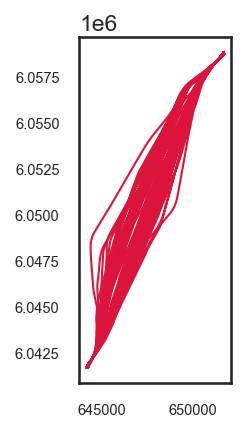

In [ ]:
query = "WITH Ports(Rodby, Puttgarden) AS (SELECT ST_MakeEnvelope(651135, 6058230, 651422, 6058548)::WKB_BLOB, ST_MakeEnvelope(644339, 6042108, 644896, 6042487)::WKB_BLOB) SELECT s.MMSI, ST_AsText(trajectory(trip)::GEOMETRY) AS Trajectory , Rodby, Puttgarden FROM Ports p, Ships s WHERE eintersects(trip, p.Rodby) AND eintersects(trip, p.Puttgarden);"
trajs=connection.execute(query).df()

trajs['geom_obj'] = trajs['Trajectory'].apply(lambda x: shapely.wkt.loads(x))
trajs_gdf = gpd.GeoDataFrame(trajs, geometry='geom_obj')
trajs_gdf['color'] = 'crimson'

_, axes = plt.subplots(figsize=(3,3), dpi=150)
trajs_gdf.plot(color=trajs_gdf["color"], ax=axes, linewidth=1)
axes.set_xlabel(axes.get_xlabel(), fontsize=1)
axes.set_ylabel(axes.get_ylabel(), fontsize=1)
axes.tick_params(axis='both', which='major', labelsize=7)
axes.tick_params(axis='both', which='minor', labelsize=7)
plt.show()

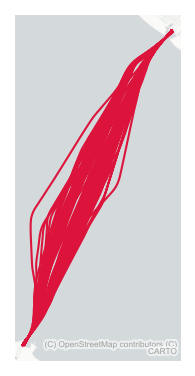

In [ ]:
trajs_gdf = trajs_gdf.set_crs(epsg=25832, allow_override=True)

trajs_gdf_3857 = trajs_gdf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(4, 3), dpi=150)

trajs_gdf_3857.plot(ax=ax, color=trajs_gdf_3857["color"], linewidth=1)

# Add basemap (choose one that doesn’t require an API key)
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron, zoom=12)

ax.set_axis_off()
for text in ax.texts:
    if "OpenStreetMap" in text.get_text():
        text.set_fontsize(4)          # smaller font
        text.set_color("gray")        # lighter color (optional)
        text.set_alpha(0.6)           # make it subtler
        text.set_position((0.98, 0.02))  # move (optional, in axes coords)
        text.set_ha('right')
plt.show()

In [ ]:

# -----------------------------
# Execute your MobilityDuck query (with ::WKB_BLOB)
# -----------------------------
query = """
WITH Ports(Rodby, Puttgarden) AS (
    SELECT 
        ST_MakeEnvelope(651135, 6058230, 651422, 6058548)::WKB_BLOB, 
        ST_MakeEnvelope(644339, 6042108, 644896, 6042487)::WKB_BLOB
)
SELECT 
    s.MMSI, 
    ST_AsText(trajectory(trip)::GEOMETRY) AS Trajectory,
    Rodby,
    Puttgarden
FROM Ports p, Ships s
WHERE eintersects(trip, p.Rodby) AND eintersects(trip, p.Puttgarden);
"""

trajs = connection.execute(query).df()

# -----------------------------
# Normalize column names
# -----------------------------
trajs.columns = [c.lower() for c in trajs.columns]

# Identify key columns
id_col = next(c for c in trajs.columns if 'mmsi' in c)
traj_col = next(c for c in trajs.columns if 'trajectory' in c)
rodby_col = next(c for c in trajs.columns if 'rodby' in c)
puttgarden_col = next(c for c in trajs.columns if 'puttgarden' in c)

# -----------------------------
# Convert WKT trajectories to Shapely geometry
# -----------------------------
trajs['geom_obj'] = trajs[traj_col].apply(wkt.loads)

# -----------------------------
# Convert WKB_BLOB ports to Shapely polygons
# -----------------------------
def wkb_blob_to_polygon(wkb_blob):
    if isinstance(wkb_blob, bytes):
        wkb_bytes = wkb_blob
    elif isinstance(wkb_blob, bytearray):
        wkb_bytes = bytes(wkb_blob)
    elif isinstance(wkb_blob, int):
        hex_str = format(wkb_blob, 'x')
        if len(hex_str) % 2:
            hex_str = '0' + hex_str
        wkb_bytes = bytes.fromhex(hex_str)
    else:
        raise TypeError(f"Unexpected type for WKB_BLOB: {type(wkb_blob)}")
    
    geom = shapely.wkb.loads(wkb_bytes)
    
    if geom.geom_type in ['Polygon', 'MultiPolygon']:
        return geom
    else:
        minx, miny, maxx, maxy = geom.bounds
        return box(minx, miny, maxx, maxy)

trajs['rodby_geom'] = trajs[rodby_col].apply(wkb_blob_to_polygon)
trajs['puttgarden_geom'] = trajs[puttgarden_col].apply(wkb_blob_to_polygon)

# -----------------------------
# Make Puttgarden slightly larger
# -----------------------------
def enlarge_polygon(polygon, factor=1.05):
    minx, miny, maxx, maxy = polygon.bounds
    width = maxx - minx
    height = maxy - miny
    dx = width * (factor - 1) / 2
    dy = height * (factor - 1) / 2
    return box(minx - dx, miny - dy, maxx + dx, maxy + dy)

trajs['puttgarden_geom'] = trajs['puttgarden_geom'].apply(lambda p: enlarge_polygon(p, 1.1))

# -----------------------------
# Create GeoDataFrame
# -----------------------------
trajs_gdf = gpd.GeoDataFrame(trajs, geometry='geom_obj')
trajs_gdf.set_crs(epsg=25832, inplace=True)
trajs_gdf = trajs_gdf.to_crs(epsg=4326)

# Convert ports to GeoDataFrame
ports_gdf = gpd.GeoDataFrame({
    'name': ['Rodby', 'Puttgarden'],
    'geometry': [trajs_gdf.iloc[0]['rodby_geom'], trajs_gdf.iloc[0]['puttgarden_geom']]
}, geometry='geometry', crs=25832)
ports_gdf = ports_gdf.to_crs(epsg=4326)

# -----------------------------
# Assign colors per ship
# -----------------------------
unique_ids = trajs_gdf[id_col].unique()
colors = cm.get_cmap('Paired', len(unique_ids))
color_map = {uid: mcolors.to_hex(colors(i)) for i, uid in enumerate(unique_ids)}
trajs_gdf['color'] = trajs_gdf[id_col].map(color_map)

# -----------------------------
# Create Folium map
# -----------------------------
center = trajs_gdf.geometry.union_all().centroid
m = folium.Map(location=[center.y, center.x], zoom_start=12, tiles='CartoDB positron')

# -----------------------------
# Add ports as rectangles with tooltips and permanent labels
# -----------------------------
for _, row in ports_gdf.iterrows():
    bounds = [[row.geometry.bounds[1], row.geometry.bounds[0]],
              [row.geometry.bounds[3], row.geometry.bounds[2]]]
    
    # Add rectangle
    folium.Rectangle(
        bounds=bounds,
        color='blue',
        weight=2,
        fill=True,
        fill_opacity=0.1,
        tooltip=row['name']
    ).add_to(m)
    
    # Add permanent label in the center
    centroid = row.geometry.centroid
    folium.map.Marker(
        [centroid.y, centroid.x],
        icon=DivIcon(
            icon_size=(150,36),
            icon_anchor=(0,0),
            html=f'<div style="font-size:10px; font-weight:regular; color:blue">{row["name"]}</div>'
        )
    ).add_to(m)

# -----------------------------
# Add trajectories with MMSI tooltips
# -----------------------------
for _, row in trajs_gdf.iterrows():
    folium.GeoJson(
        row['geom_obj'],
        style_function=lambda x, color=row['color']: {'color': color, 'weight': 1},
        tooltip=f"{id_col.upper()}: {row[id_col]}"
    ).add_to(m)

# -----------------------------
# Display map
# -----------------------------
m

In [19]:
connection.close()

In [20]:
# Reopen connection and query
connection = duckdb.connect(
    database='vessels.db',
    config={'allow_unsigned_extensions' : 'true'}
)
connection.execute("INSTALL spatial FROM core_nightly")
connection.execute(f"INSTALL '{MOBILITYDUCK_EXTENSION}'")
connection.load_extension(MOBILITYDUCK_EXTENSION)
connection.load_extension('spatial')
connection.execute("SET threads=1")
connection.execute("SET memory_limit='7000MB'")
connection.execute("SET preserve_insertion_order=false")

In [21]:
query = f"""
WITH AlertBelt(Belt) AS (
SELECT ST_MakeEnvelope(640730, 6058230, 654100, 6042487)::WKB_BLOB)  
SELECT MMSI, atGeometry(s.Trip, b.Belt::WKB_BLOB), ST_AsText(trajectory(atGeometry(s.Trip,  b.Belt))::GEOMETRY) as traj
FROM ships s TABLESAMPLE RESERVOIR (300), AlertBelt b
WHERE eintersects(s.Trip, b.Belt::WKB_BLOB) LIMIT 20;
"""

In [22]:
trajs =connection.execute(query).df()

In [23]:
trajs.head()

,mmsi,"atgeometry(s.Trip, CAST(b.Belt AS WKB_BLOB))",traj
0,245237000,"[160, 8, 0, 0, 46, 3, 94, 0, 2, 0, 0, 0, 4, 0,...",MULTILINESTRING ((654100.0595157864 6045359.15...
1,245439000,"[0, 154, 12, 0, 46, 3, 94, 0, 2, 0, 0, 0, 97, ...",MULTILINESTRING ((646263.5459751799 6042486.99...
2,245397000,"[32, 131, 56, 0, 46, 3, 94, 0, 1, 0, 0, 0, 146...",LINESTRING (651555.8607613083 6055640.66586333...
3,245901000,"[160, 204, 0, 0, 46, 3, 94, 0, 1, 0, 0, 0, 230...",LINESTRING (654100.0000043703 6047942.13773846...
4,266266000,"[128, 5, 1, 0, 46, 3, 94, 0, 1, 0, 0, 0, 39, 1...",LINESTRING (640729.9999976758 6050754.28158788...


In [46]:
# Query 6.19-0. Ships at a minimum distance within the alert belt
query = """ 
WITH AlertBelt(Belt) AS (
  SELECT ST_MakeEnvelope(640730, 6058230, 654100, 6042487)::WKB_BLOB),
BeltShips(MMSI, Trip, Trajectory) AS (
  SELECT MMSI, atGeometry(s.Trip, b.Belt), ST_AsText(trajectory(atGeometry(s.Trip, b.Belt))::GEOMETRY)  
  FROM Ships s, AlertBelt b
  WHERE eIntersects(s.Trip, b.Belt) )
SELECT s1.MMSI, s2.MMSI, s1.Trajectory, s2.Trajectory,
  st_shortestLine(s1.Trajectory::geometry, s2.Trajectory::geometry) AS Approach
FROM BeltShips s1, BeltShips s2
WHERE s1.MMSI < s2.MMSI  
;"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

#AND eDwithin(s1.Trip, s2.Trip, 500)

Execution time: 9.369528 seconds


,MMSI,MMSI_1,Trajectory,Trajectory_1,Approach
0,205196000,209341000,LINESTRING (653229.6569026313 6057168.09655345...,LINESTRING (640729.9999963015 6049291.24375874...,"[1, 4, 0, 0, 0, 0, 0, 0, 247, 88, 30, 73, 74, ..."
1,205196000,209453000,LINESTRING (653229.6569026313 6057168.09655345...,LINESTRING (646015.8310145563 6042486.99999960...,"[1, 4, 0, 0, 0, 0, 0, 0, 234, 122, 31, 73, 138..."
2,209341000,209453000,LINESTRING (640729.9999963015 6049291.24375874...,LINESTRING (646015.8310145563 6042486.99999960...,"[1, 4, 0, 0, 0, 0, 0, 0, 205, 67, 30, 73, 106,..."
3,205196000,209610000,LINESTRING (653229.6569026313 6057168.09655345...,LINESTRING (640729.9999959652 6050420.05590413...,"[1, 4, 0, 0, 0, 0, 0, 0, 228, 108, 30, 73, 90,..."
4,209341000,209610000,LINESTRING (640729.9999963015 6049291.24375874...,LINESTRING (640729.9999959652 6050420.05590413...,"[1, 4, 0, 0, 0, 0, 0, 0, 222, 207, 29, 73, 170..."


In [ ]:
# Query 6.19. Compute and display the vessel activity between the ports of Rodby and Puttgarten, within an alert belt.
query = """
    WITH AlertBelt(Belt) AS (
SELECT ST_MakeEnvelope(640730, 6058230, 654100, 6042487)::WKB_BLOB)  
SELECT MMSI, atGeometry(s.Trip, b.Belt::WKB_BLOB),
 ST_AsText(trajectory(atGeometry(s.Trip,  b.Belt))::GEOMETRY) as traj
FROM ships s , AlertBelt b
WHERE eintersects(s.Trip, b.Belt::WKB_BLOB); """
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 1.216780 seconds


,mmsi,"atgeometry(s.Trip, CAST(b.Belt AS WKB_BLOB))",traj
0,630001042,"[96, 248, 0, 0, 46, 3, 94, 0, 1, 0, 0, 0, 24, ...",LINESTRING (640729.9999973648 6049781.23813602...
1,211135000,"[160, 169, 0, 0, 46, 3, 94, 0, 1, 0, 0, 0, 190...",LINESTRING (654100.0000035341 6048417.09912668...
2,212198000,"[224, 230, 0, 0, 46, 3, 94, 0, 1, 0, 0, 0, 4, ...",LINESTRING (644109.5457183531 6048971.29448199...
3,212255000,"[32, 15, 1, 0, 46, 3, 94, 0, 1, 0, 0, 0, 50, 1...",LINESTRING (640729.9999990377 6049353.39091042...
4,211686000,"[224, 16, 1, 0, 46, 3, 94, 0, 1, 0, 0, 0, 52, ...",LINESTRING (654100.0000017086 6048333.07580877...


In [29]:
trajs['geom_obj'] = trajs['traj'].apply(lambda x: shapely.wkt.loads(x))
trajs_gdf = gpd.GeoDataFrame(trajs, geometry='geom_obj')
trajs_gdf['color'] = 'crimson'
trajs_gdf.head(2)

,mmsi,"atgeometry(s.Trip, CAST(b.Belt AS WKB_BLOB))",traj,geom_obj,color
0,245237000,"[160, 8, 0, 0, 46, 3, 94, 0, 2, 0, 0, 0, 4, 0,...",MULTILINESTRING ((654100.0595157864 6045359.15...,"MULTILINESTRING ((654100.06 6045359.151, 64822...",crimson
1,245439000,"[0, 154, 12, 0, 46, 3, 94, 0, 2, 0, 0, 0, 97, ...",MULTILINESTRING ((646263.5459751799 6042486.99...,"MULTILINESTRING ((646263.546 6042487, 646282.1...",crimson


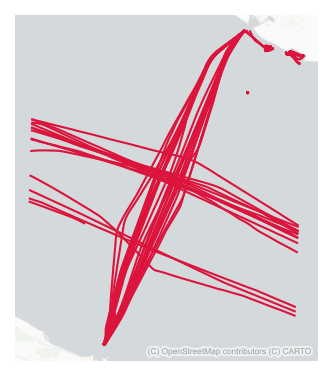

In [62]:

trajs_gdf = trajs_gdf.set_crs(epsg=25832, allow_override=True)

trajs_gdf_3857 = trajs_gdf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(4, 3), dpi=150)

trajs_gdf_3857.plot(ax=ax, color=trajs_gdf_3857["color"], linewidth=1)

# Add basemap (choose one that doesn’t require an API key)
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron, zoom=12)

ax.set_axis_off()
for text in ax.texts:
    if "OpenStreetMap" in text.get_text():
        text.set_fontsize(4)          # smaller font
        text.set_color("gray")        # lighter color (optional)
        text.set_alpha(0.6)           # make it subtler
        text.set_position((0.98, 0.02))  # move (optional, in axes coords)
        text.set_ha('right')
plt.show()

In [ ]:
# ---------------------------
# Ensure trajectories are GeoDataFrame in EPSG:4326
# ---------------------------
# Replace 'geom_obj' with your actual geometry column name
trajs_gdf_4326 = gpd.GeoDataFrame(trajs_gdf, geometry='geom_obj', crs='EPSG:25832')
trajs_gdf_4326 = trajs_gdf_4326.to_crs(epsg=4326)

# ---------------------------
#  Create the belt rectangle in EPSG:4326
# ---------------------------
belt_geom = box(640730, 6042487, 654100, 6058230)  # UTM coordinates
belt_gdf = gpd.GeoDataFrame({'name': ['belt']}, geometry=[belt_geom], crs='EPSG:25832')
belt_gdf_4326 = belt_gdf.to_crs(epsg=4326)

# ---------------------------
# Compute map bounds for auto-zoom
# ---------------------------
all_geom = pd.concat([trajs_gdf_4326.geometry, belt_gdf_4326.geometry], ignore_index=True)
all_gdf = gpd.GeoSeries(all_geom, crs='EPSG:4326')
minx, miny, maxx, maxy = all_gdf.total_bounds

# ---------------------------
# Create Folium map
# ---------------------------
m = folium.Map(location=[(miny+maxy)/2, (minx+maxx)/2], zoom_start=12)

# ---------------------------
#  Add the blue belt
# ---------------------------
belt_coords = [(pt[1], pt[0]) for pt in belt_gdf_4326.geometry.iloc[0].exterior.coords]
folium.PolyLine(
    locations=belt_coords,
    color='blue',
    weight=2,
    opacity=0.7,
    tooltip='Belt'
).add_to(m)

# ---------------------------
#  Add trajectories
# ---------------------------
for geom, mmsi, color in zip(trajs_gdf_4326.geometry,
                             trajs_gdf_4326['mmsi'],
                             trajs_gdf_4326['color']):
    if geom is None or geom.is_empty:
        continue

    # Handle LineString and MultiLineString
    if isinstance(geom, LineString):
        lines = [geom]
    elif isinstance(geom, MultiLineString):
        lines = list(geom.geoms)
    else:
        continue  # skip other types

    for line in lines:
        folium.PolyLine(
            locations=[(pt[1], pt[0]) for pt in line.coords],
            color=color,
            weight=1,
            opacity=0.7,
            tooltip=f"MMSI: {mmsi}"
        ).add_to(m)

# ---------------------------
# Auto-zoom to fit everything
# ---------------------------
m.fit_bounds([[miny, minx], [maxy, maxx]])

# ---------------------------
#  Display map
# ---------------------------
m

In [ ]:
# ---------------------------
# Trajectories in EPSG:4326
# ---------------------------
trajs_gdf_4326 = gpd.GeoDataFrame(trajs_gdf, geometry='geom_obj', crs='EPSG:25832')
trajs_gdf_4326 = trajs_gdf_4326.to_crs(epsg=4326)

# ---------------------------
#  Belt rectangle in EPSG:4326
# ---------------------------
belt_geom = box(640730, 6042487, 654100, 6058230)  # UTM coordinates
belt_gdf = gpd.GeoDataFrame({'name': ['belt']}, geometry=[belt_geom], crs='EPSG:25832')
belt_gdf_4326 = belt_gdf.to_crs(epsg=4326)

# ---------------------------
# Compute map bounds
# ---------------------------
all_geom = pd.concat([trajs_gdf_4326.geometry, belt_gdf_4326.geometry], ignore_index=True)
all_gdf = gpd.GeoSeries(all_geom, crs='EPSG:4326')
minx, miny, maxx, maxy = all_gdf.total_bounds

# ---------------------------
# Create Folium map
# ---------------------------
m = folium.Map(location=[(miny+maxy)/2, (minx+maxx)/2], zoom_start=12)

# ---------------------------
#  Add shaded belt
# ---------------------------
belt_coords = [(pt[1], pt[0]) for pt in belt_gdf_4326.geometry.iloc[0].exterior.coords]
folium.Polygon(
    locations=belt_coords,
    color='blue',
    weight=2,
    fill=True,
    fill_color='blue',
    fill_opacity=0.1,  # slightly shaded
    tooltip='Belt'
).add_to(m)

# ---------------------------
#  Add trajectories with popups
# ---------------------------
for geom, mmsi, color, name, ship_type, speed in zip(
    trajs_gdf_4326.geometry,
    trajs_gdf_4326['mmsi'],
    trajs_gdf_4326['color'],
    trajs_gdf_4326.get('ship_name', ['N/A']*len(trajs_gdf_4326)),
    trajs_gdf_4326.get('ship_type', ['N/A']*len(trajs_gdf_4326)),
    trajs_gdf_4326.get('speed', ['N/A']*len(trajs_gdf_4326))
):
    if geom is None or geom.is_empty:
        continue

    if isinstance(geom, LineString):
        lines = [geom]
    elif isinstance(geom, MultiLineString):
        lines = list(geom.geoms)
    else:
        continue

    popup_html = f"""
    <b>MMSI:</b> {mmsi}<br>
    <b>Ship Name:</b> {name}<br>
    <b>Type:</b> {ship_type}<br>
    <b>Speed:</b> {speed}
    """

    for line in lines:
        folium.PolyLine(
            locations=[(pt[1], pt[0]) for pt in line.coords],
            color=color,
            weight=1,
            opacity=0.7,
            tooltip=f"MMSI: {mmsi}",
            popup=folium.Popup(popup_html, max_width=300)
        ).add_to(m)

# ---------------------------
#  Auto-zoom to fit everything
# ---------------------------
m.fit_bounds([[miny, minx], [maxy, maxx]])

# ---------------------------
#  Display map
# ---------------------------
m

In [86]:
query = """WITH AlertBelt(Belt) AS 
(SELECT ST_MakeEnvelope(640730, 6058230, 654100, 6042487)::WKB_BLOB) 
SELECT MMSI, atGeometry(s.Trip, b.Belt), 
ST_AsText(trajectory(atGeometry(s.Trip,  b.Belt))::GEOMETRY) as traj FROM Ships s TABLESAMPLE RESERVOIR (300), 
AlertBelt b WHERE eintersects(s.Trip, b.Belt);"""
trajs=connection.execute(query).df()

In [87]:
trajs.head()

,mmsi,"atgeometry(s.Trip, b.Belt)",traj
0,209992000,"[128, 212, 0, 0, 46, 3, 94, 0, 1, 0, 0, 0, 239...",LINESTRING (654100.000000754 6048336.928865205...
1,563182600,"[160, 144, 1, 0, 46, 3, 94, 0, 1, 0, 0, 0, 198...",LINESTRING (640729.9999978812 6050358.04514678...
2,305425000,"[64, 118, 3, 0, 46, 3, 94, 0, 1, 0, 0, 0, 241,...",LINESTRING (640729.9999982426 6050082.14412854...
3,306157000,"[64, 200, 0, 0, 46, 3, 94, 0, 1, 0, 0, 0, 225,...",LINESTRING (654100.0000053905 6048699.85324027...
4,354294000,"[224, 216, 0, 0, 46, 3, 94, 0, 1, 0, 0, 0, 244...",LINESTRING (654100.0000085611 6046706.91374636...


In [108]:
# Query 6.20. Compute and display the vessels that during a time interval have been at 300m from 
# each other, displaying the points, the closest distance, and the position of the vessels".
query = """
WITH Timespan(Period) AS (
SELECT tstzspan '[2024-03-01 11:00:00, 2024-03-01 23:30:00)' ),
TimeShips(MMSI, Trip) AS (
SELECT MMSI, atTime(s.Trip, t.Period)
FROM Ships s TABLESAMPLE RESERVOIR (600), Timespan t
WHERE atTime(s.Trip, t.Period) IS NOT NULL ),
TimeClosestShips(MMSI1, MMSI2, ClosestDist, TimeAtClosestDist, Trip1, Trip2) AS (
SELECT s1.MMSI, s2.MMSI, startValue(atMin(s1.Trip <-> s2.Trip)),
startTimestamp(atMin(s1.Trip <-> s2.Trip)), s1.Trip, s2.Trip
FROM TimeShips s1, TimeShips s2
WHERE s1.MMSI < s2.MMSI AND eDwithin(s1.Trip, s2.Trip, 300) AND
startValue(atMin(s1.Trip <-> s2.Trip)) < 300 )
SELECT t.MMSI1, t.MMSI2, t.ClosestDist, t.TimeAtClosestDist,
valueAtTimestamp(Trip1, TimeAtClosestDist) AS Point1,
valueAtTimestamp(Trip2, TimeAtClosestDist) AS Point2
FROM TimeClosestShips t; """
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 207.204517 seconds


,MMSI1,MMSI2,ClosestDist,TimeAtClosestDist,Point1,Point2
0,209415000,211265610,63.623083,2024-03-01 15:09:01.855413-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 92, 173, 9, 1...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 222, 87, 33, ..."
1,211291170,211363300,46.184968,2024-03-01 11:34:34-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 225, 138, 145...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 93, 22, 219, ..."
2,209415000,211445190,77.244753,2024-03-01 14:44:59.161067-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 85, 241, 242,...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 6, 177, 162, ..."
3,209415000,211457860,86.153056,2024-03-01 17:25:14.858704-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 67, 221, 107,...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 33, 24, 19, 1..."
4,211274960,211457860,52.976498,2024-03-01 15:57:21.093464-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 210, 218, 49,...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 40, 154, 113,..."


In [39]:
query = f"""
WITH Timespan(Period) AS (
SELECT tstzspan '[2024-03-01 11:00:00, 2024-03-01 23:30:00)' ),
TimeShips(MMSI, Trip) AS (
SELECT MMSI, atTime(s.Trip, t.Period)
FROM Ships s TABLESAMPLE RESERVOIR (300), Timespan t
WHERE atTime(s.Trip, t.Period) IS NOT NULL ),
TimeClosestShips(MMSI1, MMSI2, ClosestDist, TimeAtClosestDist, Trip1, Trip2) AS (
SELECT s1.MMSI, s2.MMSI, startValue(atMin(s1.Trip <-> s2.Trip)),
startTimestamp(atMin(s1.Trip <-> s2.Trip)), s1.Trip, s2.Trip
FROM TimeShips s1, TimeShips s2
WHERE s1.MMSI < s2.MMSI AND eDwithin(s1.Trip, s2.Trip, 300) AND
startValue(atMin(s1.Trip <-> s2.Trip)) < 300 )
SELECT t.MMSI1, t.MMSI2, t.ClosestDist, t.TimeAtClosestDist,
valueAtTimestamp(Trip1, TimeAtClosestDist) AS Point1,
valueAtTimestamp(Trip2, TimeAtClosestDist) AS Point2
FROM TimeClosestShips t;
"""

In [40]:
trajs =connection.execute(query).df()

In [85]:
trajs.head()

,MMSI1,MMSI2,ClosestDist,TimeAtClosestDist,Point1,Point2
0,211302570,219000191,87.124676,2024-03-01 15:06:25-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 80, 60, 194, ...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 140, 186, 6, ..."
1,219000855,219006219,11.902335,2024-03-01 17:25:43.944113-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 3, 22, 254, 2...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 247, 65, 196,..."
2,219006164,219023274,258.592295,2024-03-01 17:27:45-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 58, 53, 158, ...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 73, 138, 191,..."
3,219019010,219023274,177.065445,2024-03-01 17:17:40-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 41, 244, 76, ...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 239, 78, 5, 2..."
4,219004266,219023766,237.672222,2024-03-01 20:03:27-03:00,"[1, 1, 0, 0, 32, 232, 100, 0, 0, 175, 157, 170...","[1, 1, 0, 0, 32, 232, 100, 0, 0, 74, 204, 45, ..."


In [41]:
query = f"""
WITH Timespan(Period) AS (
SELECT tstzspan '[2024-03-01 11:00:00, 2024-03-01 23:30:00)' ),
TimeShips(MMSI, Trip) AS (
SELECT MMSI, atTime(s.Trip, t.Period)
FROM Ships s TABLESAMPLE RESERVOIR (100), Timespan t
WHERE atTime(s.Trip, t.Period) IS NOT NULL ),
TimeClosestShips(MMSI1, MMSI2, ClosestDist, TimeAtClosestDist, Trip1, Trip2) AS (
SELECT s1.MMSI, s2.MMSI, startValue(atMin(s1.Trip <-> s2.Trip)),
startTimestamp(atMin(s1.Trip <-> s2.Trip)), s1.Trip, s2.Trip
FROM TimeShips s1, TimeShips s2
WHERE s1.MMSI < s2.MMSI AND eDwithin(s1.Trip, s2.Trip, 300) AND
startValue(atMin(s1.Trip <-> s2.Trip)) < 300 )
SELECT t.MMSI1, t.MMSI2, t.ClosestDist, t.TimeAtClosestDist,
ST_astext(valueAtTimestamp(Trip1, TimeAtClosestDist)::geometry) AS Point1,
ST_astext(valueAtTimestamp(Trip2, TimeAtClosestDist)::geometry)AS Point2
FROM TimeClosestShips t;
"""

In [42]:
trajs =connection.execute(query).df()
trajs.head()

,MMSI1,MMSI2,ClosestDist,TimeAtClosestDist,Point1,Point2
0,210803000,211624750,98.112578,2024-03-01 14:54:47.221119-03:00,POINT (702009.717293074 6007664.838037714),POINT (701921.028498534 6007622.881207328)
1,219005763,219015186,140.648992,2024-03-01 11:05:36.634302-03:00,POINT (475595.0120612513 6331094.633335816),POINT (475716.11042532837 6331023.097853737)
2,219022300,219024647,94.325533,2024-03-01 12:26:36-03:00,POINT (594524.450456141 6398233.967220489),POINT (594555.0269925762 6398144.73504236)
3,210803000,636092297,36.284054,2024-03-01 14:12:17.471387-03:00,POINT (701737.3382363323 6001360.380067335),POINT (701703.279852561 6001347.867711709)


In [ ]:
# -----------------------------
# Define query
# -----------------------------
query = f"""
WITH Timespan(Period) AS (
    SELECT tstzspan '[2024-03-01 11:00:00, 2024-03-01 23:30:00)' ),
TimeShips(MMSI, Trip) AS (
    SELECT MMSI, atTime(s.Trip, t.Period)
    FROM Ships s TABLESAMPLE RESERVOIR (500), Timespan t
    WHERE atTime(s.Trip, t.Period) IS NOT NULL ),
TimeClosestShips(MMSI1, MMSI2, ClosestDist, TimeAtClosestDist, Trip1, Trip2) AS (
    SELECT s1.MMSI, s2.MMSI,
        startValue(atMin(s1.Trip <-> s2.Trip)),
        startTimestamp(atMin(s1.Trip <-> s2.Trip)),
        s1.Trip, s2.Trip
    FROM TimeShips s1, TimeShips s2
    WHERE s1.MMSI < s2.MMSI
      AND eDwithin(s1.Trip, s2.Trip, 300)
      AND startValue(atMin(s1.Trip <-> s2.Trip)) < 300
)
SELECT 
    t.MMSI1, t.MMSI2, t.ClosestDist, t.TimeAtClosestDist,
    ST_AsText(valueAtTimestamp(Trip1, TimeAtClosestDist)::geometry) AS Point1,
    ST_AsText(valueAtTimestamp(Trip2, TimeAtClosestDist)::geometry) AS Point2
FROM TimeClosestShips t;
"""

# -----------------------------
#  Execute query
# -----------------------------
df = connection.execute(query).df()

# -----------------------------
#  Convert coordinates EPSG:25832 → EPSG:4326
# -----------------------------
transformer = Transformer.from_crs("EPSG:25832", "EPSG:4326", always_xy=True).transform

def convert_point(wkt_point):
    geom = wkt.loads(wkt_point)
    return transform(transformer, geom)

df["p1"] = df["Point1"].map(convert_point)
df["p2"] = df["Point2"].map(convert_point)

# -----------------------------
# Create Folium map
# -----------------------------
# Center map roughly at average point
center_lat = (df["p1"].map(lambda p: p.y).mean() + df["p2"].map(lambda p: p.y).mean()) / 2
center_lon = (df["p1"].map(lambda p: p.x).mean() + df["p2"].map(lambda p: p.x).mean()) / 2

m = folium.Map(location=[center_lat, center_lon], zoom_start=10, tiles="CartoDB Positron")

# -----------------------------
# Add points and connecting lines
# -----------------------------
for _, row in df.iterrows():
    p1 = row["p1"]
    p2 = row["p2"]

    # Point 1 (red)
    folium.CircleMarker(
        location=[p1.y, p1.x],
        radius=4,
        color="red",
        fill=True,
        fill_opacity=0.9,
        popup=f"MMSI1: {row['MMSI1']}<br>ClosestDist: {row['ClosestDist']:.1f} m"
    ).add_to(m)

    # Point 2 (blue)
    folium.CircleMarker(
        location=[p2.y, p2.x],
        radius=2,
        color="blue",
        fill=True,
        fill_opacity=0.9,
        popup=f"MMSI2: {row['MMSI2']}<br>Time: {row['TimeAtClosestDist']}"
    ).add_to(m)

    # Line connecting points
    folium.PolyLine(
        locations=[[p1.y, p1.x], [p2.y, p2.x]],
        color="purple",
        weight=2,
        opacity=0.6
    ).add_to(m)

# -----------------------------
#  Display map
# -----------------------------
m

In [ ]:
# Query. "".
query = """
WITH Timespan(Period) AS (
SELECT tstzspan '[2024-03-01 06:00:00, 2024-03-01 13:00:00)' )
SELECT MMSI, astext(atTime(s.Trip, t.Period)) as triptime
FROM Ships s, Timespan t
WHERE atTime(s.Trip, t.Period) IS NOT NULL
 ;
 """
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 3.515305 seconds


,mmsi,triptime
0,2655150,[POINT(682296.3924622597 6398757.150724542)@20...
1,111265586,[POINT(818682.5864107412 6228702.950621524)@20...
2,211226990,[POINT(554292.6149544579 6077064.1021294985)@2...
3,211266470,[POINT(701955.0269223226 6005362.5503886575)@2...
4,211297990,[POINT(479754.57979632786 6041579.71399597)@20...


In [ ]:
query = f"""
WITH Timespan(Period) AS (
SELECT tstzspan '[2024-03-01 11:00:00, 2024-03-01 15:30:00)' )
SELECT MMSI, astext(atTime(s.Trip, t.Period)) as triptime
FROM Ships s, Timespan t
WHERE atTime(s.Trip, t.Period) IS NOT NULL 
 ;
"""

In [161]:
trajs=connection.execute(query).df()

In [162]:
trajs

,mmsi,triptime
0,2655150,[POINT(682296.3924622597 6398757.150724542)@20...
1,111265586,[POINT(818682.5864107412 6228702.950621524)@20...
2,211226990,[POINT(554292.6149544579 6077064.1021294985)@2...
3,211266470,[POINT(701955.0269223226 6005362.5503886575)@2...
4,211297990,[POINT(479754.57979632786 6041579.71399597)@20...
...,...,...
2493,992191515,[POINT(207879.5171890183 6254436.4903167235)@2...
2494,992191518,[POINT(227063.28062021942 6188781.470886675)@2...
2495,992191527,[POINT(232989.27260105265 6182626.003365496)@2...
2496,992191538,[POINT(235816.99865132873 6182784.4471070375)@...


In [44]:
# Query 6.21. "Compute and display the  trajectories of vessels that during a time interval have been at 300m from each other.".

query = """
WITH Timespan(Period) AS (
SELECT tstzspan '[2024-03-01 11:00:00, 2024-03-01 23:30:00)' ),
TimeShips(MMSI, Trip) AS (
SELECT MMSI, atTime(s.Trip, t.Period)
FROM Ships s TABLESAMPLE RESERVOIR (600), Timespan t
WHERE atTime(s.Trip, t.Period) IS NOT NULL )
SELECT s1.MMSI, s2.MMSI, s1.Trip, s2.Trip, ST_AsText(trajectory(s1.Trip)::GEOMETRY) as traj1, ST_AsText(trajectory(s2.Trip)::GEOMETRY) as traj2
FROM TimeShips s1, TimeShips s2
WHERE s1.MMSI < s2.MMSI AND eDwithin(s1.Trip, s2.Trip, 300)  ;
 ;
 """
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 178.807250 seconds


,MMSI,MMSI_1,Trip,Trip_1,traj1,traj2
0,210195000,211274960,"[32, 108, 11, 0, 46, 2, 94, 0, 12, 13, 0, 0, 1...","[224, 97, 0, 0, 46, 2, 94, 0, 110, 0, 0, 0, 11...",LINESTRING (708411.259535373 6045193.029857993...,LINESTRING (553190.5592988682 6024191.46825602...
1,211316900,211325200,"[32, 42, 10, 0, 46, 2, 94, 0, 156, 11, 0, 0, 1...","[96, 50, 11, 0, 46, 2, 94, 0, 202, 12, 0, 0, 2...",LINESTRING (472270.8757947694 6104637.92588434...,LINESTRING (472338.62668272323 6104739.9794232...
2,211101000,211409370,"[128, 254, 7, 0, 46, 2, 94, 0, 33, 9, 0, 0, 33...","[32, 26, 0, 0, 46, 2, 94, 0, 28, 0, 0, 0, 28, ...",LINESTRING (454632.91534315085 6068169.2961705...,LINESTRING (454629.9625692189 6068223.11314917...
3,211101000,211413470,"[128, 254, 7, 0, 46, 2, 94, 0, 33, 9, 0, 0, 33...","[0, 248, 13, 0, 46, 2, 94, 0, 245, 15, 0, 0, 2...",LINESTRING (454632.91534315085 6068169.2961705...,LINESTRING (458134.6877929137 6069649.78566022...
4,211532870,211534760,"[0, 188, 0, 0, 46, 2, 94, 0, 213, 0, 0, 0, 213...","[32, 103, 0, 0, 46, 2, 94, 0, 116, 0, 0, 0, 11...",LINESTRING (767610.5285302848 6049791.22455777...,LINESTRING (766110.5109432321 6056213.90638834...


In [ ]:
query = f"""
WITH Timespan(Period) AS (
SELECT tstzspan '[2024-03-01 11:00:00, 2024-03-01 23:30:00)' ),
TimeShips(MMSI, Trip) AS (
SELECT MMSI, atTime(s.Trip, t.Period)
FROM Ships s TABLESAMPLE RESERVOIR (100), Timespan t
WHERE atTime(s.Trip, t.Period) IS NOT NULL )
SELECT s1.MMSI, s2.MMSI, s1.Trip, s2.Trip, ST_AsText(trajectory(s1.Trip)::GEOMETRY) as traj1, ST_AsText(trajectory(s2.Trip)::GEOMETRY) as traj2
FROM TimeShips s1, TimeShips s2
WHERE s1.MMSI < s2.MMSI AND eDwithin(s1.Trip, s2.Trip, 300)  ;
"""

In [72]:
trajs=connection.execute(query).df()
trajs

,MMSI,MMSI_1,Trip,Trip_1,traj1,traj2
0,211409370,218342000,"[32, 26, 0, 0, 46, 2, 94, 0, 28, 0, 0, 0, 28, ...","[32, 222, 0, 0, 46, 2, 94, 0, 252, 0, 0, 0, 25...",LINESTRING (454629.9625692189 6068223.11314917...,LINESTRING (454681.4586389575 6068222.08105457...
1,219005805,219005901,"[0, 104, 0, 0, 46, 2, 94, 0, 117, 0, 0, 0, 117...","[224, 70, 12, 0, 46, 2, 94, 0, 6, 14, 0, 0, 6,...",LINESTRING (445665.5163863694 6247357.65084512...,LINESTRING (445697.46365161554 6247423.4205874...
2,219003959,219007471,"[192, 196, 0, 0, 46, 2, 94, 0, 223, 0, 0, 0, 2...","[0, 23, 1, 0, 46, 2, 94, 0, 61, 1, 0, 0, 61, 1...",LINESTRING (557507.6599550699 6383778.61416720...,LINESTRING (557632.7031044338 6383742.97802169...
3,219013968,219015186,"[32, 78, 1, 0, 46, 2, 94, 0, 124, 1, 0, 0, 124...","[32, 236, 0, 0, 46, 2, 94, 0, 12, 1, 0, 0, 12,...",LINESTRING (475795.67080842744 6331043.2251448...,LINESTRING (475715.50779536547 6331023.5871575...
4,219003959,219015595,"[192, 196, 0, 0, 46, 2, 94, 0, 223, 0, 0, 0, 2...","[96, 175, 13, 0, 46, 2, 94, 0, 162, 15, 0, 0, ...",LINESTRING (557507.6599550699 6383778.61416720...,LINESTRING (557152.6934003055 6383683.02114249...
5,219020150,219022300,"[160, 88, 1, 0, 46, 2, 94, 0, 136, 1, 0, 0, 13...","[0, 70, 12, 0, 46, 2, 94, 0, 5, 14, 0, 0, 5, 1...",LINESTRING (594573.0151162584 6398170.73246145...,LINESTRING (594515.5133725432 6398234.35934160...
6,219020150,219024647,"[160, 88, 1, 0, 46, 2, 94, 0, 136, 1, 0, 0, 13...","[64, 172, 0, 0, 46, 2, 94, 0, 195, 0, 0, 0, 19...",LINESTRING (594573.0151162584 6398170.73246145...,LINESTRING (594558.7319274935 6398143.43548679...
7,211267710,219825000,"[96, 3, 0, 0, 46, 2, 94, 0, 2, 0, 0, 0, 2, 0, ...","[96, 17, 0, 0, 46, 2, 94, 0, 18, 0, 0, 0, 18, ...",LINESTRING (482449.07606278185 5968223.6705155...,LINESTRING (476264.5685601474 5977587.19898439...
8,219011225,219862000,"[192, 54, 11, 0, 46, 2, 94, 0, 207, 12, 0, 0, ...","[64, 206, 9, 0, 46, 2, 94, 0, 51, 11, 0, 0, 51...",LINESTRING (445282.027260142 6206965.102044665...,LINESTRING (445388.3056953355 6206802.38412716...
9,219015103,219862000,"[96, 197, 11, 0, 46, 2, 94, 0, 114, 13, 0, 0, ...","[64, 206, 9, 0, 46, 2, 94, 0, 51, 11, 0, 0, 51...",LINESTRING (445147.2055511924 6206942.32782934...,LINESTRING (445388.3056953355 6206802.38412716...


In [ ]:
# ---------------------------
# Convert WKT to Shapely geometries
# ---------------------------
trajs['traj1_geom'] = trajs['traj1'].apply(wkt.loads)
trajs['traj2_geom'] = trajs['traj2'].apply(wkt.loads)

# ---------------------------
# Create GeoDataFrames
# ---------------------------
gdf1 = gpd.GeoDataFrame(trajs, geometry='traj1_geom', crs='EPSG:25832')
gdf2 = gpd.GeoDataFrame(trajs, geometry='traj2_geom', crs='EPSG:25832')

# ---------------------------
#  Project to Web Mercator for basemap
# ---------------------------
gdf1 = gdf1.to_crs(epsg=3857)
gdf2 = gdf2.to_crs(epsg=3857)

# ---------------------------
# Plot
# ---------------------------
fig, ax = plt.subplots(figsize=(6, 5), dpi=150)

gdf1.plot(ax=ax, color='red', linewidth=1, label='traj1')
gdf2.plot(ax=ax, color='green', linewidth=1, label='traj2')
ax.legend(fontsize=6, loc='upper right') 
# Add basemap

 
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_axis_off()
ax.legend()
plt.show()

In [ ]:
# ---------------------------
#  Convert WKT to Shapely geometries
# ---------------------------
trajs['traj1_geom'] = trajs['traj1'].apply(wkt.loads)
trajs['traj2_geom'] = trajs['traj2'].apply(wkt.loads)

# ---------------------------
# Create GeoDataFrames
# ---------------------------
gdf1 = gpd.GeoDataFrame(trajs.copy(), geometry='traj1_geom', crs='EPSG:25832')
gdf2 = gpd.GeoDataFrame(trajs.copy(), geometry='traj2_geom', crs='EPSG:25832')

# ---------------------------
# Convert to EPSG:4326
# ---------------------------
gdf1_4326 = gdf1.to_crs(epsg=4326)
gdf2_4326 = gdf2.to_crs(epsg=4326)

# ---------------------------
# Compute map bounds
# ---------------------------
all_geom = pd.concat([gdf1_4326.geometry, gdf2_4326.geometry], ignore_index=True)
all_gdf = gpd.GeoSeries(all_geom, crs='EPSG:4326')
minx, miny, maxx, maxy = all_gdf.total_bounds

# ---------------------------
#  Create Folium map
# ---------------------------
m = folium.Map(location=[(miny+maxy)/2, (minx+maxx)/2], zoom_start=12, tiles='CartoDB positron')

# ---------------------------
#  Function to add trajectories
# ---------------------------
def add_traj(geom, color, tooltip):
    if geom is None or geom.is_empty:
        return
    lines = [geom] if isinstance(geom, LineString) else list(geom.geoms)
    for line in lines:
        folium.PolyLine(
            locations=[(pt[1], pt[0]) for pt in line.coords],
            color=color,
            weight=2,
            opacity=0.7,
            tooltip=tooltip
        ).add_to(m)

# Column names
geom_col1 = 'traj1_geom'
geom_col2 = 'traj2_geom'

# ---------------------------
#  Add trajectories
# ---------------------------
for _, row in gdf1_4326.iterrows():
    add_traj(row[geom_col1], 'red', f"traj1 MMSI: {row['MMSI']}")

for _, row in gdf2_4326.iterrows():
    add_traj(row[geom_col2], 'green', f"traj2 MMSI: {row['MMSI']}")

# ---------------------------
# Add small legend
# ---------------------------
legend_html = """
<div style="
position: fixed; 
bottom: 10px; left: 10px; width: 120px; height: 60px; 
background-color: white; 
border:2px solid grey; z-index:9999; font-size:12px;
padding: 5px;">
<b>Legend</b><br>
<span style="color:red;">&#9679;</span> traj1<br>
<span style="color:green;">&#9679;</span> traj2
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

# ---------------------------
# Auto-zoom
# ---------------------------
m.fit_bounds([[miny, minx], [maxy, maxx]])

# ---------------------------
#  Display map
# ---------------------------
m

In [160]:
# Query 6.22. Trajectories within a radius of 500m around the port of Copenhaghen
query = query = """
WITH Port AS (
    SELECT ST_Point(726765.3929300838, 6178705.65508127) AS port_geom
),
PortBuffer AS (
    SELECT ST_Buffer(port_geom, 500) AS buf
    FROM Port
)
SELECT 
    s.MMSI AS mmsi,
    ST_AsText(trajectory(s.Trip)::GEOMETRY) AS trip_wkt,
    pb.buf::WKB_BLOB AS buffer_wkb
FROM Ships s, PortBuffer pb
WHERE eIntersects(s.Trip, pb.buf::WKB_BLOB);
"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 0.959543 seconds


,mmsi,trip_wkt,buffer_wkb
0,219012397,LINESTRING (726001.0840879756 6176144.06981576...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 199, ..."
1,219021572,LINESTRING (731803.8935871699 6166530.11431631...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 199, ..."
2,219012277,LINESTRING (726924.6543074973 6178117.35970757...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 199, ..."
3,219002857,LINESTRING (725921.1708786516 6176228.24087939...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 199, ..."
4,219005252,LINESTRING (726931.9964891874 6178119.08062864...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 199, ..."


In [ ]:
from pyproj import Transformer

transformer = Transformer.from_crs("EPSG:4326", "EPSG:25832", always_xy=True)
e, n = transformer.transform(12.60900, 55.70100)
print(e, n)

726765.3929300838 6178705.65508127


In [ ]:
# -----------------------------
#  Run your MobilityDuck query
# -----------------------------
query = """
WITH Port AS (
    SELECT ST_Point(726765.3929300838, 6178705.65508127) AS port_geom
),
PortBuffer AS (
    SELECT ST_Buffer(port_geom, 500) AS buf
    FROM Port
)
SELECT 
    s.MMSI AS mmsi,
    ST_AsText(trajectory(s.Trip)::GEOMETRY) AS trip_wkt,
    pb.buf::WKB_BLOB AS buffer_wkb
FROM Ships s, PortBuffer pb
WHERE eIntersects(s.Trip, pb.buf::WKB_BLOB);
"""
df = connection.execute(query).df()

# -----------------------------
# Convert geometries
# -----------------------------
df["trip_geom"] = df["trip_wkt"].apply(shapely.wkt.loads)

buffer_val = df["buffer_wkb"].iloc[0]
if isinstance(buffer_val, int):
    buffer_bytes = buffer_val.to_bytes((buffer_val.bit_length() + 7) // 8, byteorder='big')
elif isinstance(buffer_val, (bytearray, memoryview)):
    buffer_bytes = bytes(buffer_val)
else:
    buffer_bytes = buffer_val

buffer_polygon = shapely.wkb.loads(buffer_bytes)

# -----------------------------
# GeoDataFrame
# -----------------------------
gdf = gpd.GeoDataFrame(df, geometry="trip_geom", crs="EPSG:25832")
gdf_wgs = gdf.to_crs(epsg=4326)

# -----------------------------
# Map setup
# -----------------------------
center = gdf_wgs.geometry.iloc[0].centroid
m = folium.Map(location=[center.y, center.x], zoom_start=12, tiles="CartoDB positron")

# -----------------------------
# Draw true circle for port buffer
# -----------------------------
buffer_center = buffer_polygon.centroid
buffer_center_wgs = gpd.GeoSeries([buffer_center], crs="EPSG:25832").to_crs(epsg=4326).iloc[0]

folium.Circle(
    location=[buffer_center_wgs.y, buffer_center_wgs.x],
    radius=500,  # 1 km
    color="red",
    weight=1,     # thinner line
    fill=True,
    fill_color="red",
    fill_opacity=0.2,
    tooltip="Copenhagen Port 1 km buffer"
).add_to(m)

# -----------------------------
# Draw trajectories
# -----------------------------
unique_ids = gdf_wgs["mmsi"].unique()
colors = cm.get_cmap("tab20", len(unique_ids))
color_map = {mmsi: mcolors.to_hex(colors(i)) for i, mmsi in enumerate(unique_ids)}

for _, row in gdf_wgs.iterrows():
    folium.GeoJson(
        row["trip_geom"],
        style_function=lambda x, color=color_map[row["mmsi"]]: {"color": color, "weight": 2},
        tooltip=f"MMSI: {row['mmsi']}"
    ).add_to(m)

# -----------------------------
#  Permanent port label
# -----------------------------
folium.Marker(
    location=[buffer_center_wgs.y, buffer_center_wgs.x],
    icon=folium.DivIcon(
        html='<div style="font-size:14px; color:red"><b>Copenhagen Port</b></div>'
    )
).add_to(m)

# -----------------------------
#  Show map
# -----------------------------
m

In [142]:
df = connection.execute(query).df()
print(df.columns)

Index(['mmsi'], dtype='object')


In [23]:
# Query 6.22 - variation. Trajectories within a radius of 500m around the port of Copenhaghen
query = query = """
WITH Port AS (
    SELECT ST_Point(726765.3929300838, 6178705.65508127) AS port_geom
),
PortBuffer AS (
    SELECT ST_Buffer(port_geom, 2500) AS buf
    FROM Port
)
 SELECT
  s.trip, atGeometry(s.trip, m.buf::WKB_BLOB)
 FROM
 ships s, PortBuffer m  
 WHERE eIntersects(s.Trip, m.buf::WKB_BLOB);

"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 1.459812 seconds


,trip,"atgeometry(s.trip, CAST(m.buf AS WKB_BLOB))"
0,"[64, 184, 32, 0, 46, 2, 94, 0, 99, 37, 0, 0, 9...","[160, 47, 6, 0, 46, 3, 94, 0, 1, 0, 0, 0, 14, ..."
1,"[160, 16, 5, 0, 46, 2, 94, 0, 200, 5, 0, 0, 20...","[160, 0, 2, 0, 46, 3, 94, 0, 4, 0, 0, 0, 64, 2..."
2,"[160, 98, 2, 0, 46, 2, 94, 0, 184, 2, 0, 0, 18...","[128, 114, 0, 0, 46, 3, 94, 0, 5, 0, 0, 0, 119..."
3,"[64, 110, 33, 0, 46, 2, 94, 0, 51, 38, 0, 0, 5...","[0, 112, 33, 0, 46, 3, 94, 0, 1, 0, 0, 0, 51, ..."
4,"[160, 97, 18, 0, 46, 2, 94, 0, 0, 21, 0, 0, 0,...","[32, 114, 6, 0, 46, 3, 94, 0, 2, 0, 0, 0, 88, ..."


In [ ]:
# -----------------------------
# Run your MobilityDuck query
# -----------------------------
query = """
WITH Port AS (
    SELECT ST_Point(726765.3929300838, 6178705.65508127) AS port_geom
),
PortBuffer AS (
    SELECT ST_Buffer(port_geom, 1000) AS buf
    FROM Port
)
SELECT s.MMSI AS mmsi,
astext(stops(atGeometry(s.trip, pb.buf::WKB_BLOB),0.0, interval '40 minutes')),   
ST_AsText(trajectory(atGeometry(s.trip, pb.buf::WKB_BLOB))::GEOMETRY) AS trip_wkt,
pb.buf::WKB_BLOB AS buffer_wkb
FROM
ships s, PortBuffer pb
WHERE eIntersects(s.trip, pb.buf::WKB_BLOB) AND
astext(stops(atGeometry(s.trip, pb.buf::WKB_BLOB),0.0, interval '40 minutes')) IS NOT NULL
AND ST_GEOMETRYTYPE(trajectory(atGeometry(s.trip, pb.buf::WKB_BLOB))::GEOMETRY)<> 'POINT';
"""
df = connection.execute(query).df()

 
# -----------------------------
#  Convert geometries
# -----------------------------
df["trip_geom"] = df["trip_wkt"].apply(shapely.wkt.loads)

buffer_val = df["buffer_wkb"].iloc[0]
if isinstance(buffer_val, int):
    buffer_bytes = buffer_val.to_bytes((buffer_val.bit_length() + 7) // 8, byteorder='big')
elif isinstance(buffer_val, (bytearray, memoryview)):
    buffer_bytes = bytes(buffer_val)
else:
    buffer_bytes = buffer_val

buffer_polygon = shapely.wkb.loads(buffer_bytes)

# -----------------------------
#  GeoDataFrame
# -----------------------------
gdf = gpd.GeoDataFrame(df, geometry="trip_geom", crs="EPSG:25832")
gdf_wgs = gdf.to_crs(epsg=4326)

# -----------------------------
#  Map setup
# -----------------------------
center = gdf_wgs.geometry.iloc[0].centroid
m = folium.Map(location=[center.y, center.x], zoom_start=12, tiles="CartoDB positron")

# -----------------------------
#  Draw true circle for port buffer
# -----------------------------
buffer_center = buffer_polygon.centroid
buffer_center_wgs = gpd.GeoSeries([buffer_center], crs="EPSG:25832").to_crs(epsg=4326).iloc[0]

folium.Circle(
    location=[buffer_center_wgs.y, buffer_center_wgs.x],
    radius=1000,  # 1 km
    color="red",
    weight=1,     # thinner line
    fill=True,
    fill_color="red",
    fill_opacity=0.2,
    tooltip="Copenhagen Port 1 km buffer"
).add_to(m)

# -----------------------------
#  Draw trajectories
# -----------------------------
unique_ids = gdf_wgs["mmsi"].unique()
colors = cm.get_cmap("Set1", len(unique_ids))
color_map = {mmsi: mcolors.to_hex(colors(i)) for i, mmsi in enumerate(unique_ids)}

for _, row in gdf_wgs.iterrows():
    folium.GeoJson(
        row["trip_geom"],
        style_function=lambda x, color=color_map[row["mmsi"]]: {"color": color, "weight": 2},
        tooltip=f"MMSI: {row['mmsi']}"
    ).add_to(m)

# -----------------------------
# Permanent port label
# -----------------------------
folium.Marker(
    location=[buffer_center_wgs.y, buffer_center_wgs.x],
    icon=folium.DivIcon(
        html='<div style="font-size:14px; color:black"><b>Copenhagen Port</b></div>'
    )
).add_to(m)

# -----------------------------
# Show map
# -----------------------------
m

In [ ]:
from pyproj import Transformer

transformer = Transformer.from_crs("EPSG:4326", "EPSG:25832", always_xy=True)
e, n = transformer.transform(12.60900, 55.70100)
print(e, n)

In [ ]:
# Query 6.23. Trajectories within a radius of 1000m around the port of Copenhaghen which stopped for at least 20 minutes
query = query = """
WITH Port AS (
    SELECT ST_Point(726765.3929300838, 6178705.65508127) AS port_geom
),
PortBuffer AS (
    SELECT ST_Buffer(port_geom, 1000) AS buf
    FROM Port
)
SELECT s.MMSI AS mmsi,
astext(stops(atGeometry(s.trip, pb.buf::WKB_BLOB),0.0, interval '20 minutes')),   
ST_AsText(trajectory(atGeometry(s.trip, pb.buf::WKB_BLOB))::GEOMETRY) AS trip_wkt,
pb.buf::WKB_BLOB AS buffer_wkb
FROM
ships s, PortBuffer pb
WHERE eIntersects(s.trip, pb.buf::WKB_BLOB) AND
astext(stops(atGeometry(s.trip, pb.buf::WKB_BLOB),0.0, interval '40 minutes')) IS NOT NULL AND
ST_GEOMETRYTYPE(trajectory(atGeometry(s.trip, pb.buf::WKB_BLOB))::GEOMETRY)<> 'POINT';
"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.tail()

Execution time: 6.204683 seconds


,mmsi,"astext(stops(atgeometry(s.trip, CAST(pb.buf AS WKB_BLOB)), 0.0, CAST('40 minutes' AS INTERVAL)))",trip_wkt,buffer_wkb
0,219014727,{[POINT(726091.6618055995 6178239.8328332575)@...,MULTILINESTRING ((726012.6868779607 6178276.21...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 199, ..."
1,244723000,{[POINT(727401.4090674086 6179389.305101981)@2...,"LINESTRING (726813.55254027 6179561.241838938,...","[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 199, ..."


In [28]:
query = """
SELECT asText(stops(tgeompoint '[Point(1 1)@2001-01-01, 
Point(1 1)@2001-01-02, Point(2 2)@2001-01-03, 
Point(2 2)@2001-01-04]', 0.0, interval '10 minutes')); 
"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.head()

Execution time: 0.012598 seconds


,"astext(stops(CAST('[Point(1 1)@2001-01-01, \nPoint(1 1)@2001-01-02, Point(2 2)@2001-01-03, \nPoint(2 2)@2001-01-04]' AS tgeompoint), 0.0, CAST('10 minutes' AS INTERVAL)))"
0,"{[POINT(1 1)@2001-01-01 00:00:00-03, POINT(1 1..."


In [ ]:

#{[POINT(1 1)@2001-01-01 00:00:00+00, POINT(1 1)@2001-01-02 00:00:00+00], [POINT(2 2)@2001-01-03 00:00:00+00, POINT(2 2)@2001-01-04 00:00:00+00]}

In [47]:
transformer = Transformer.from_crs("EPSG:4326", "EPSG:25832", always_xy=True)
#e, n = transformer.transform(13.0059, 55.6118)
e, n = transformer.transform(13.012, 55.5918)
print(e, n)

752775.9137447166 6167956.005944439


In [95]:
# Query 6.24. MALMO. Trajectories within a radius of 1000m around the port of Malmo which stopped for at least 20 minutes
query = query = """
WITH Port AS (
    SELECT ST_Point(752775.9137447166, 6167956.005944439) AS port_geom
),
PortBuffer AS (
    SELECT ST_Buffer(port_geom, 5000) AS buf
    FROM Port
)
SELECT s.MMSI AS mmsi,
  asText(stops(atGeometry(s.trip, pb.buf::WKB_BLOB),1000.0, interval '1 hour')),
  ST_AsText(trajectory(atGeometry(s.trip, pb.buf::WKB_BLOB))::GEOMETRY) AS trip_wkt,
  pb.buf::WKB_BLOB AS buffer_wkb,
  StartTimestamp(stops(atGeometry(s.trip, pb.buf::WKB_BLOB),1000.0, interval '1 hour')) AS start_time  
FROM ships s, PortBuffer pb
WHERE eIntersects(s.trip, pb.buf::WKB_BLOB) AND
      astext(stops(atGeometry(s.trip, pb.buf::WKB_BLOB),1000.0, interval '1 hour')) IS NOT NULL AND
      ST_GEOMETRYTYPE(trajectory(atGeometry(s.trip, pb.buf::WKB_BLOB))::GEOMETRY)<> 'POINT';
"""
t0 = time.perf_counter()
answer = connection.execute(query).df()
t1 = time.perf_counter()
print(f"Execution time: {t1 - t0:.6f} seconds")
answer.tail()
 
 

Execution time: 6.104044 seconds


,mmsi,"astext(stops(atgeometry(s.trip, CAST(pb.buf AS WKB_BLOB)), 1000.0, CAST('1 hour' AS INTERVAL)))",trip_wkt,buffer_wkb,start_time
12,265625700,{[POINT(753900.8772487256 6171655.858776311)@2...,LINESTRING (753900.8772487256 6171655.85877631...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 245, ...",2024-02-29 21:17:19-03:00
13,265628170,{[POINT(753987.6570026367 6171690.921380292)@2...,LINESTRING (753987.6570026367 6171690.92138029...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 245, ...",2024-02-29 21:02:48-03:00
14,265719650,{[POINT(751193.7916008857 6170456.6253623655)@...,LINESTRING (751193.7916008857 6170456.62536236...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 245, ...",2024-02-29 21:02:44-03:00
15,265794430,{[POINT(747959.9699753532 6168151.304685969)@2...,LINESTRING (747959.9699753532 6168151.30468596...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 245, ...",2024-03-01 08:48:17-03:00
16,538004477,{[POINT(752645.8837252944 6172917.315400401)@2...,LINESTRING (752645.8837252944 6172917.31540040...,"[1, 3, 0, 0, 0, 1, 0, 0, 0, 33, 0, 0, 0, 245, ...",2024-02-29 21:00:23-03:00


In [ ]:
# -----------------------------
# Run your MobilityDuck query
# -----------------------------
query = """
WITH Port AS (
    SELECT ST_Point(752775.9137447166, 6167956.005944439) AS port_geom
),
PortBuffer AS (
    SELECT ST_Buffer(port_geom, 6000) AS buf
    FROM Port
)
SELECT s.MMSI AS mmsi,
astext(stops(atGeometry(s.trip, pb.buf::WKB_BLOB), 0.0, interval '1 hour')),   
ST_AsText(trajectory(atGeometry(s.trip, pb.buf::WKB_BLOB))::GEOMETRY) AS trip_wkt,
pb.buf::WKB_BLOB AS buffer_wkb,
StartTimestamp(stops(atGeometry(s.trip, pb.buf::WKB_BLOB), 0., interval '1 hour')) AS start_time  
FROM
ships s, PortBuffer pb
WHERE eIntersects(s.trip, pb.buf::WKB_BLOB) AND
astext(stops(atGeometry(s.trip, pb.buf::WKB_BLOB), 0.0, interval '1 hour')) IS NOT NULL AND
ST_GEOMETRYTYPE(trajectory(atGeometry(s.trip, pb.buf::WKB_BLOB))::GEOMETRY)<> 'POINT';
"""
df = connection.execute(query).df()

 
# -----------------------------
# Convert geometries
# -----------------------------
df["trip_geom"] = df["trip_wkt"].apply(shapely.wkt.loads)

buffer_val = df["buffer_wkb"].iloc[0]
if isinstance(buffer_val, int):
    buffer_bytes = buffer_val.to_bytes((buffer_val.bit_length() + 7) // 8, byteorder='big')
elif isinstance(buffer_val, (bytearray, memoryview)):
    buffer_bytes = bytes(buffer_val)
else:
    buffer_bytes = buffer_val

buffer_polygon = shapely.wkb.loads(buffer_bytes)

# -----------------------------
# GeoDataFrame
# -----------------------------
gdf = gpd.GeoDataFrame(df, geometry="trip_geom", crs="EPSG:25832")
gdf_wgs = gdf.to_crs(epsg=4326)

# -----------------------------
# Map setup
# -----------------------------
center = gdf_wgs.geometry.iloc[0].centroid
m = folium.Map(location=[center.y, center.x], zoom_start=12, tiles="CartoDB positron")

# -----------------------------
# Draw true circle for port buffer
# -----------------------------
buffer_center = buffer_polygon.centroid
buffer_center_wgs = gpd.GeoSeries([buffer_center], crs="EPSG:25832").to_crs(epsg=4326).iloc[0]

folium.Circle(
    location=[buffer_center_wgs.y, buffer_center_wgs.x],
    radius=6000,  # 5km
    color="red",
    weight=1,     # thinner line
    fill=True,
    fill_color="red",
    fill_opacity=0.2, 
).add_to(m)

# -----------------------------
# Draw trajectories
# -----------------------------
unique_ids = gdf_wgs["mmsi"].unique()
colors = cm.get_cmap("Set1", len(unique_ids))
color_map = {mmsi: mcolors.to_hex(colors(i)) for i, mmsi in enumerate(unique_ids)}

for _, row in gdf_wgs.iterrows():
    folium.GeoJson(
        row["trip_geom"],
        style_function=lambda x, color=color_map[row["mmsi"]]: {"color": color, "weight": 2},
        tooltip=f"MMSI: {row['mmsi']}"
    ).add_to(m)

# -----------------------------
# Permanent port label
# -----------------------------
#folium.Marker(
#    location=[buffer_center_wgs.y, buffer_center_wgs.x],
#    icon=folium.DivIcon(
#        html='<div style="font-size:14px; color:black"><b>Copenhagen Port</b></div>'
#    )
#).add_to(m)

# -----------------------------
# Show map
# -----------------------------
m